In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision.datasets import CIFAR10

In [ ]:
print(f"Torch version: {torch.__version__}")
print(f"Torchvision version: {torchvision.__version__}")

Torch version: 2.11.0+cpu
Torchvision version: 0.26.0+cpu


In [ ]:
from torch.utils.data import dataloader
import torchvision.transforms as transforms

transform=transforms.Compose([
    transforms.Resize((32, 32)), # This line resizes the input image
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

In [ ]:
trainset=CIFAR10("root=./data",train=True,download=True,transform=transform)
testset=CIFAR10("root=./data",train=False,download=True,transform=transform)

In [ ]:
from collections import Counter

print("Class names:", trainset.classes)
# To count the occurrences of each class label in the dataset
label_counts = Counter(trainset.targets)
print("Class label distribution:", label_counts)

Class names: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Class label distribution: Counter({6: 5000, 9: 5000, 4: 5000, 1: 5000, 2: 5000, 7: 5000, 8: 5000, 3: 5000, 5: 5000, 0: 5000})


In [ ]:
import pandas as pd

# Convert trainset.targets (which is a list) to a pandas Series and then apply value_counts()
pd.Series(trainset.targets).value_counts()

,count
6,5000
9,5000
4,5000
1,5000
2,5000
7,5000
8,5000
3,5000
5,5000
0,5000


In [ ]:
print(trainset.classes)
print(len(trainset))

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
50000


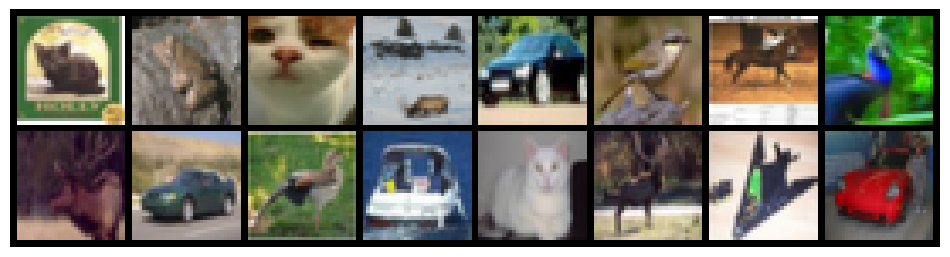

['cat', 'frog', 'cat', 'deer', 'automobile', 'bird', 'horse', 'bird', 'deer', 'automobile']


<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt
import torchvision

images, labels = next(iter(trainloader))

# Unnormalize
images = images / 2 + 0.5

# Show first 10
grid = torchvision.utils.make_grid(images[:16])
plt.figure(figsize=(12,12))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.show()
plt.tight_layout()

print([trainset.classes[label] for label in labels[:10]])

In [ ]:
from torch.utils.data import DataLoader
trainloader=DataLoader(trainset,batch_size=64,shuffle=True)
testloader=DataLoader(testset,batch_size=64)

# **Build CNN**

In [ ]:
from torch.nn.modules import MaxPool2d
class CNN(nn.Module):
  def __init__(self):
    super(CNN,self).__init__()
    self.conv_layers=nn.Sequential(
        nn.Conv2d(3,32 ,kernel_size=3,padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2,2) , # kernel-size  is 2,stride=2


        nn.Conv2d(32,64 ,kernel_size=3,padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2,2),  # kernel-size  is 2,stride=2


        nn.Conv2d(64,128 ,kernel_size=3,padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2,2)  # kernel-size  is 2,stride=2

    )

    self.fc_layer=nn.Sequential(
        nn.Linear(4*4*128,256),
        nn.ReLU(),
        nn.Linear(256,10)
    )


  def forward(self,x):
    x=self.conv_layers(x)
    x=x.view(x.size(0), -1)
    x=self.fc_layer(x)
    return x

In [ ]:
model=CNN()

In [ ]:
criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters())

# **Training CNN**

In [ ]:
#training the cnn
epochs=10

for epoch in range(epochs):
  epoch_training_loss=0.0
  for images,labels in trainloader:
    optimizer.zero_grad()
    output=model.forward(images)
    loss=criterion(output,labels)
    loss.backward()
    optimizer.step()
    epoch_training_loss+=loss.item()
  print(f"epoch={epoch+1}/{epochs} & loss={epoch_training_loss/len(trainloader)}")

epoch=1/10 & loss=0.06064075167525558
epoch=2/10 & loss=0.060268409274187404
epoch=3/10 & loss=0.06387885643929705
epoch=4/10 & loss=0.06650690844984722
epoch=5/10 & loss=0.05731977298757528
epoch=6/10 & loss=0.054131622892654684
epoch=7/10 & loss=0.04902225829757806
epoch=8/10 & loss=0.06269795632371239
epoch=9/10 & loss=0.050162867101094244
epoch=10/10 & loss=0.05891684180816643


In [ ]:
#Evaluate our CNN
correct_labels=0
total_labels=0
model.eval()
with torch.no_grad():
  for images,labels in testloader:
    output=model.forward(images)
    _, predicted = torch.max(output,1)
    correct_labels=(predicted == labels).sum().item()
    total_labels=labels.size(0)


In [ ]:
print(f"Accuracy= {correct_labels/total_labels *100}")

Accuracy= 81.25


In [ ]:
from PIL import Image

classes = trainset.classes

def predict(image_path):
    # Ensure PIL.Image is correctly loaded
    image = Image.open(image_path).convert("RGB")

    image = transform(image)
    image = image.unsqueeze(0)   # Add batch dimension

    with torch.no_grad():
        output = model(image)
        prediction = output.argmax(1).item()

    print("Prediction:", classes[prediction])

In [ ]:
predict("/content/download (2).jfif")

Prediction: cat


In [ ]:
import pickle

with open('model.pkl','wb') as f:
  pickle.dump(model,f)

In [ ]:
torch.save(model.state_dict(), "model.pth")